Độ nhiễu: 0.5
MSE: 0.1634
R2 Score: 0.9507
---------------------


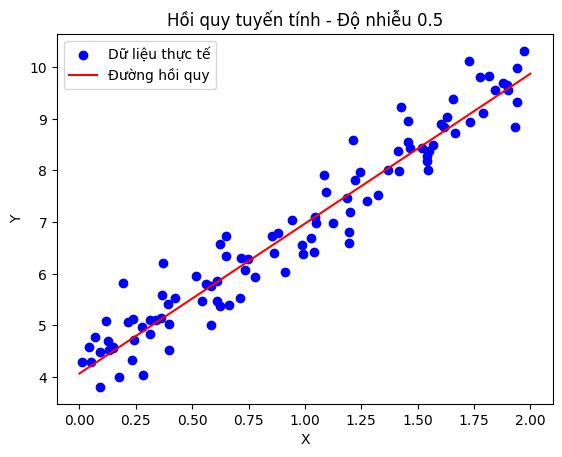

Độ nhiễu: 2
MSE: 8.2861
R2 Score: 0.1066
---------------------


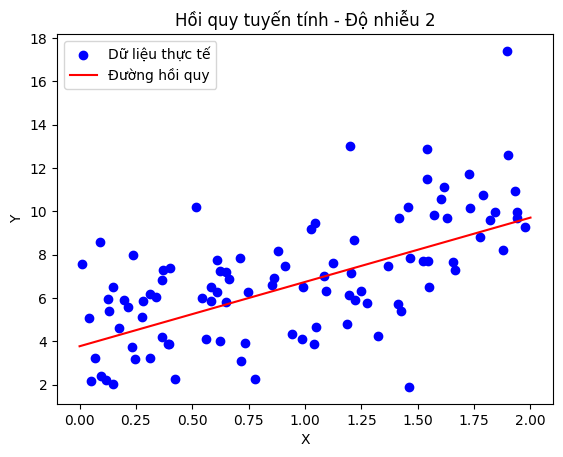

Độ nhiễu: 5
MSE: 8.9182
R2 Score: 0.3807
---------------------


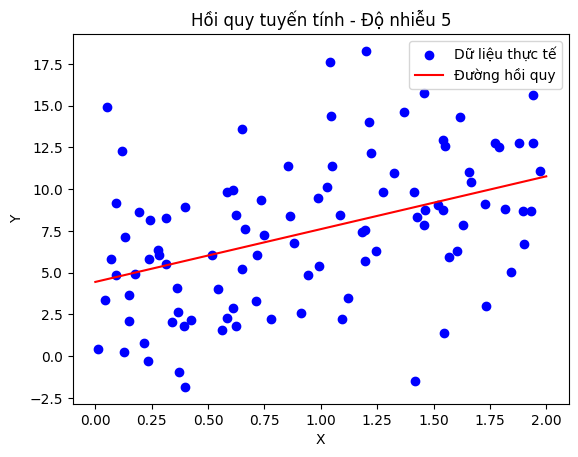

Độ nhiễu: 10
MSE: 103.2463
R2 Score: -0.0217
---------------------


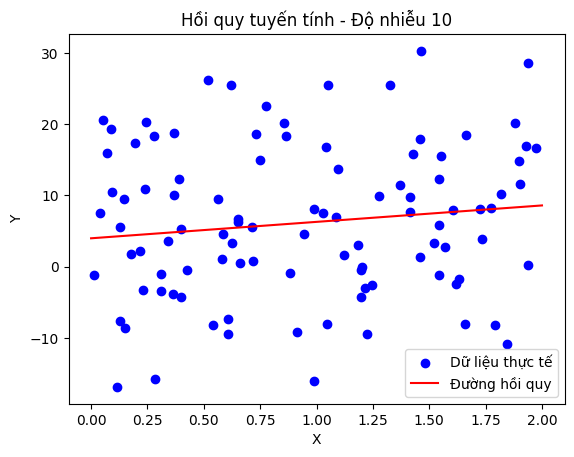

In [1]:
#Bài 1:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Tạo dữ liệu
np.random.seed(42)
X = 2 * np.random.rand(100, 1)

# Thử với các mức độ nhiễu khác nhau
noise_levels = [0.5, 2, 5, 10]

for noise in noise_levels:
    # Tạo dữ liệu có nhiễu
    y = 4 + 3 * X.ravel() + noise * np.random.randn(100)

    # Chia dữ liệu
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    # Huấn luyện mô hình
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Dự đoán
    y_pred = model.predict(X_test)

    # Đánh giá
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"Độ nhiễu: {noise}")
    print(f"MSE: {mse:.4f}")
    print(f"R2 Score: {r2:.4f}")
    print("---------------------")

    # Vẽ biểu đồ
    X_line = np.linspace(0, 2, 100).reshape(-1, 1)

    plt.scatter(X, y, color="blue", label="Dữ liệu thực tế")
    plt.plot(X_line, model.predict(X_line),
             color="red", label="Đường hồi quy")
    plt.title(f"Hồi quy tuyến tính - Độ nhiễu {noise}")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.legend()
    plt.show()


Ngưỡng dự đoán: 0.5
Accuracy: 0.8250
Ma trận nhầm lẫn:
[[16  3]
 [ 4 17]]
----------------------
Ngưỡng dự đoán: 0.6
Accuracy: 0.8000
Ma trận nhầm lẫn:
[[16  3]
 [ 5 16]]
----------------------
Ngưỡng dự đoán: 0.7
Accuracy: 0.8000
Ma trận nhầm lẫn:
[[17  2]
 [ 6 15]]
----------------------


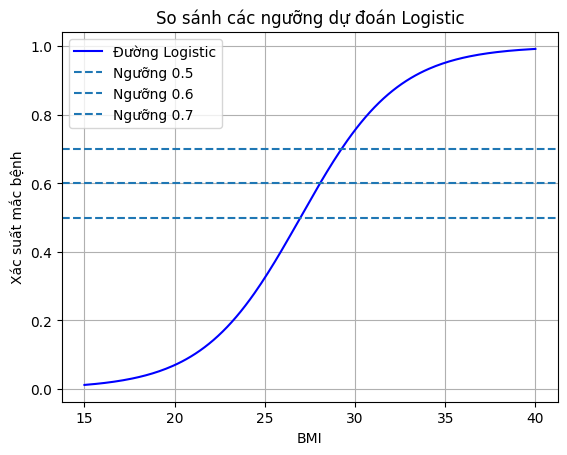

In [2]:
#Bài 2:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

# Tạo dữ liệu BMI giả lập
np.random.seed(42)
BMI = np.random.uniform(15, 40, 200).reshape(-1, 1)

# Xác suất mắc bệnh giả lập
prob = 1 / (1 + np.exp(-(BMI.ravel() - 27) / 3))
y = np.random.binomial(1, prob)

# Chia dữ liệu
X_train, X_test, y_train, y_test = train_test_split(
    BMI, y, test_size=0.2, random_state=42
)

# Huấn luyện mô hình
model = LogisticRegression()
model.fit(X_train, y_train)

# Dự đoán xác suất
y_prob = model.predict_proba(X_test)[:, 1]

# Thử các ngưỡng khác nhau
thresholds = [0.5, 0.6, 0.7]

for threshold in thresholds:
    y_pred = (y_prob >= threshold).astype(int)

    accuracy = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    print(f"Ngưỡng dự đoán: {threshold}")
    print(f"Accuracy: {accuracy:.4f}")
    print("Ma trận nhầm lẫn:")
    print(cm)
    print("----------------------")

# Vẽ đường Logistic và các ngưỡng
bmi_range = np.linspace(15, 40, 200).reshape(-1, 1)
prob_range = model.predict_proba(bmi_range)[:, 1]

plt.plot(bmi_range, prob_range, color="blue",
         label="Đường Logistic")

for threshold in thresholds:
    plt.axhline(threshold, linestyle="--",
                label=f"Ngưỡng {threshold}")

plt.xlabel("BMI")
plt.ylabel("Xác suất mắc bệnh")
plt.title("So sánh các ngưỡng dự đoán Logistic")
plt.legend()
plt.grid(True)
plt.show()

Số lượng mẫu: 506
Số đặc trưng: 13
Số mẫu huấn luyện: 404
Số mẫu kiểm tra: 102

KẾT QUẢ ĐÁNH GIÁ
MSE: 24.291119474973485
R2 Score: 0.6687594935356325

So sánh 10 mẫu đầu:
   Giá thực tế  Giá dự đoán
0         23.6    28.996724
1         32.4    36.025565
2         13.6    14.816944
3         22.8    25.031979
4         16.1    18.769880
5         20.0    23.254429
6         17.8    17.662538
7         14.0    14.341190
8         19.6    23.013207
9         16.8    20.632456


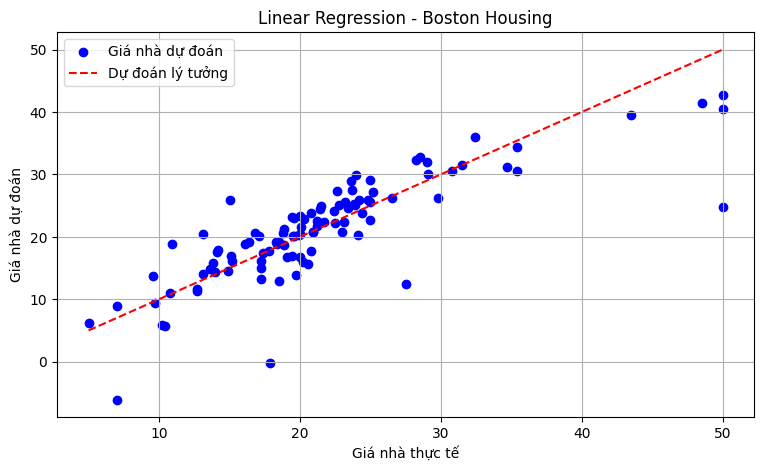

In [3]:
#Bài 3:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tải bộ dữ liệu Boston Housing
url = "https://lib.stat.cmu.edu/datasets/boston"

raw_df = pd.read_csv(url, sep=r"\s+", skiprows=22, header=None)

# 2. Xử lý dữ liệu
X = np.hstack([
    raw_df.values[::2, :],
    raw_df.values[1::2, :2]
])

y = raw_df.values[1::2, 2]

# 3. Kiểm tra dữ liệu
print("Số lượng mẫu:", X.shape[0])
print("Số đặc trưng:", X.shape[1])

# 4. Chia tập huấn luyện và kiểm tra
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Số mẫu huấn luyện:", len(X_train))
print("Số mẫu kiểm tra:", len(X_test))

# 5. Tạo mô hình hồi quy tuyến tính
model = LinearRegression()

# 6. Huấn luyện mô hình
model.fit(X_train, y_train)

# 7. Dự đoán giá nhà
y_pred = model.predict(X_test)

# 8. Đánh giá mô hình
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nKẾT QUẢ ĐÁNH GIÁ")
print("MSE:", mse)
print("R2 Score:", r2)

# 9. So sánh thực tế và dự đoán
result = pd.DataFrame({
    "Giá thực tế": y_test,
    "Giá dự đoán": y_pred
})

print("\nSo sánh 10 mẫu đầu:")
print(result.head(10))

# 10. Vẽ biểu đồ
plt.figure(figsize=(9, 5))

plt.scatter(y_test, y_pred, color="blue",
            label="Giá nhà dự đoán")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--",
    label="Dự đoán lý tưởng"
)

plt.xlabel("Giá nhà thực tế")
plt.ylabel("Giá nhà dự đoán")
plt.title("Linear Regression - Boston Housing")
plt.legend()
plt.grid(True)
plt.show()
